# TabNet for Cardiovascular Disease Prediction
### Explainable Artificial Intelligence for CVD Prediction — Q1 Paper

**Model:** TabNet — Attentive Interpretable Tabular Learning (Arik & Pfister, 2021)  
**Dataset:** Heart_disease_clean.csv (68,534 records, 13 features)  
**Key Novelty:** TabNet has built-in sequential attention masks — a **native XAI mechanism** that serves as the 5th XAI paradigm alongside permutation importance, SHAP, LIME, and Integrated Gradients.

**Reference:**  
Arik, S. O., & Pfister, T. (2021). TabNet: Attentive interpretable tabular learning. *Proceedings of the AAAI Conference on Artificial Intelligence*, 35(8), 6679–6687.

---

**Notebook Sections:**
1. Import Libraries
2. Load & Preprocess Data
3. Feature Engineering
4. Train / Validation / Test Split (70/15/15)
5. TabNet Architecture Overview
6. Train TabNet Model
7. Training Curve
8. Evaluate on Test Set
9. TabNet Native Feature Importance (Attention Masks)
10. Step-wise Attention Heatmap
11. SHAP Explainability on TabNet
12. Local Explanation — Individual Patient
13. Partial Dependence Plots
14. Confusion Matrix
15. ROC & Precision-Recall Curves
16. Compare TabNet vs. All Other Models
17. Cross-Method XAI Consistency Heatmap
18. Save Model

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
import shap
import warnings
import os
warnings.filterwarnings('ignore')

import torch
from pytorch_tabnet.tab_model import TabNetClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.inspection import PartialDependenceDisplay
from sklearn.metrics import (
    roc_auc_score, accuracy_score, f1_score,
    precision_score, recall_score,
    confusion_matrix, classification_report,
    roc_curve, precision_recall_curve,
    average_precision_score
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

print('All libraries imported successfully!')
print(f'PyTorch version : {torch.__version__}')
print(f'CUDA available  : {torch.cuda.is_available()}')
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Device          : {DEVICE}')
if DEVICE == 'cuda':
    print(f'GPU             : {torch.cuda.get_device_name(0)}')

All libraries imported successfully!
PyTorch version : 2.6.0+cu124
CUDA available  : True
Device          : cuda
GPU             : NVIDIA GeForce GTX 1650


## 2. Load & Preprocess Data

In [2]:
# ── Load dataset ──────────────────────────────────────────────
df = pd.read_csv('Heart_disease_clean.csv')

print('Dataset shape:', df.shape)
print('\nColumns:')
for i, col in enumerate(df.columns):
    print(f'  [{i}] {col}')
print('\nMissing values:', df.isnull().sum().sum())

Dataset shape: (68653, 11)

Columns:
  [0] Gender (0: female, 1: male)
  [1] age(years)
  [2] BMI
  [3] ap_hi(Systolic blood pressure)
  [4] ap_lo(Diastolic blood pressure)
  [5] cholesterol(1: normal, 2: above normal, 3: well above normal)
  [6] Glucose(1: normal, 2: above normal, 3: well above normal)
  [7] smoking
  [8] alcohol
  [9] active
  [10] cardiovascular disease

Missing values: 0


In [3]:
# ── Encode target ─────────────────────────────────────────────
# TabNet requires integer labels (0 or 1)
# Handle both string and numeric target formats
target_col = 'cardiovascular disease'

if df[target_col].dtype == object:
    df['target'] = (df[target_col] == 'has cardiovascular disease').astype(int)
else:
    df['target'] = df[target_col].astype(int)

df = df.drop(columns=[target_col])

print('Target encoded: 1 = CVD  |  0 = No CVD')
print(df['target'].value_counts())
print(f'\nClass balance: {df["target"].mean():.4f} positive (CVD)')

Target encoded: 1 = CVD  |  0 = No CVD
target
0    34706
1    33947
Name: count, dtype: int64

Class balance: 0.4945 positive (CVD)


In [4]:
# ── Additional data cleaning ──────────────────────────────────
# Remove any remaining physiologically impossible values
before = len(df)

sbp_col = 'ap_hi(Systolic blood pressure)'
dbp_col = 'ap_lo(Diastolic blood pressure)'

df = df[
    df['BMI'].between(10, 60) &
    (df[dbp_col] < df[sbp_col])
].reset_index(drop=True)

print(f'Rows before : {before}')
print(f'Rows after  : {len(df)}')
print(f'Removed     : {before - len(df)} rows')

Rows before : 68653
Rows after  : 68534
Removed     : 119 rows


## 3. Feature Engineering

In [5]:
# ── Engineer 3 haemodynamic features (same as original paper) ─
sbp_col  = 'ap_hi(Systolic blood pressure)'
dbp_col  = 'ap_lo(Diastolic blood pressure)'
chol_col = 'cholesterol(1: normal, 2: above normal, 3: well above normal)'
gluc_col = 'Glucose(1: normal, 2: above normal, 3: well above normal)'

# Pulse Pressure = SBP - DBP
df['PP']  = df[sbp_col] - df[dbp_col]

# Mean Arterial Pressure = (SBP + 2*DBP) / 3
df['MAP'] = (df[sbp_col] + 2 * df[dbp_col]) / 3

# Risk Factor Count — composite of modifiable CVD risk factors
df['risk_count'] = (
    (df[chol_col] > 1).astype(int) +
    (df[gluc_col] > 1).astype(int) +
    df['smoking'] +
    df['alcohol'] +
    (1 - df['active'])   # inactive = a risk factor
)

# ── Define feature list ───────────────────────────────────────
FEATURES = [
    'Gender (0: female, 1: male)',
    'age(years)',
    'BMI',
    'ap_hi(Systolic blood pressure)',
    'ap_lo(Diastolic blood pressure)',
    'cholesterol(1: normal, 2: above normal, 3: well above normal)',
    'Glucose(1: normal, 2: above normal, 3: well above normal)',
    'smoking',
    'alcohol',
    'active',
    'PP',
    'MAP',
    'risk_count'
]

# Short names used in plots
FEAT_NAMES = [
    'Gender', 'Age', 'BMI', 'SBP', 'DBP',
    'Cholesterol', 'Glucose', 'Smoking',
    'Alcohol', 'Active', 'PP', 'MAP', 'RiskCount'
]

# TabNet requires float32
X = df[FEATURES].values.astype(np.float32)
y = df['target'].values

print(f'Feature matrix X : {X.shape}')
print(f'Target vector  y : {y.shape}')
print(f'Features         : {len(FEATURES)}')
print(f'\nFeature names    : {FEAT_NAMES}')

Feature matrix X : (68534, 13)
Target vector  y : (68534,)
Features         : 13

Feature names    : ['Gender', 'Age', 'BMI', 'SBP', 'DBP', 'Cholesterol', 'Glucose', 'Smoking', 'Alcohol', 'Active', 'PP', 'MAP', 'RiskCount']


## 4. Train / Validation / Test Split (70 / 15 / 15)

In [6]:
# ── Stratified 70/15/15 split ─────────────────────────────────
X_tmp, X_test, y_tmp, y_test = train_test_split(
    X, y, test_size=0.15, random_state=RANDOM_STATE, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_tmp, y_tmp, test_size=0.1765, random_state=RANDOM_STATE, stratify=y_tmp
)

print(f'Training   set : {len(X_train):>6} records  ({len(X_train)/len(X)*100:.1f}%)')
print(f'Validation set : {len(X_val):>6} records  ({len(X_val)/len(X)*100:.1f}%)')
print(f'Test       set : {len(X_test):>6} records  ({len(X_test)/len(X)*100:.1f}%)')
print(f'\nClass balance — Train: {y_train.mean():.4f}  Val: {y_val.mean():.4f}  Test: {y_test.mean():.4f}')

Training   set :  47971 records  (70.0%)
Validation set :  10282 records  (15.0%)
Test       set :  10281 records  (15.0%)

Class balance — Train: 0.4944  Val: 0.4945  Test: 0.4944


In [7]:
# ── StandardScaler ─────────────────────────────────────────────
# Fit ONLY on training data to prevent data leakage
scaler     = StandardScaler()
X_train_sc = scaler.fit_transform(X_train).astype(np.float32)
X_val_sc   = scaler.transform(X_val).astype(np.float32)
X_test_sc  = scaler.transform(X_test).astype(np.float32)

print('StandardScaler fitted on training data only.')
print('Feature means (training):', scaler.mean_[:5].round(3), '...')

StandardScaler fitted on training data only.
Feature means (training): [  0.347  53.358  27.444 126.532  81.23 ] ...


## 5. TabNet Architecture Overview

TabNet processes tabular data through a sequence of **decision steps**. At each step:

1. **Attentive Transformer** — a softmax attention layer selects which features to focus on at this step. The selection is sparse (controlled by `lambda_sparse`), so most features are ignored.
2. **Feature Transformer** — a GLU (Gated Linear Unit) network processes only the selected features.
3. The outputs of all steps are summed to form the final classification.

**Why this matters for XAI:**  
The attention masks from each step are directly interpretable — they show *which features the model chose to look at* at each decision step. Summing across steps gives a per-feature importance score with no post-hoc explanation method needed.

| Parameter | Meaning | Value |
|---|---|---|
| `n_d` | Width of decision step output | 32 |
| `n_a` | Width of attention embedding | 32 |
| `n_steps` | Number of sequential attention steps | 5 |
| `gamma` | Feature reuse penalty | 1.5 |
| `lambda_sparse` | Sparsity regularisation | 1e-4 |

## 6. Train TabNet Model

In [8]:
# ── Instantiate TabNet ────────────────────────────────────────
tabnet = TabNetClassifier(
    # Architecture
    n_d              = 32,
    n_a              = 32,
    n_steps          = 5,
    gamma            = 1.5,
    n_independent    = 2,
    n_shared         = 2,
    # Regularisation
    lambda_sparse    = 1e-4,
    momentum         = 0.02,
    clip_value       = 2.0,
    # Optimiser
    optimizer_fn     = torch.optim.Adam,
    optimizer_params = {'lr': 2e-2, 'weight_decay': 1e-5},
    # Learning rate scheduler
    scheduler_fn     = torch.optim.lr_scheduler.StepLR,
    scheduler_params = {'step_size': 50, 'gamma': 0.9},
    # Other
    seed             = RANDOM_STATE,
    verbose          = 10,
    device_name      = DEVICE
)

print(f'TabNet instantiated on: {DEVICE}')
if DEVICE == 'cuda':
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    print('Training will take ~2-3 minutes on GPU.')
else:
    print('Training will take ~10-20 minutes on CPU.')

TabNet instantiated on: cuda
GPU: NVIDIA GeForce GTX 1650
Training will take ~2-3 minutes on GPU.


In [9]:
# ── Train TabNet ──────────────────────────────────────────────
tabnet.fit(
    X_train     = X_train_sc,
    y_train     = y_train,
    eval_set    = [(X_val_sc, y_val)],
    eval_name   = ['val'],
    eval_metric = ['auc'],
    max_epochs  = 200,
    patience    = 20,           # Early stopping patience
    batch_size  = 1024,
    virtual_batch_size = 256,   # Ghost batch normalisation
    num_workers = 0,
    drop_last   = False
)

print('\nTraining complete!')
print(f'Best validation AUC : {max(tabnet.history["val_auc"]):.4f}')
print(f'Best epoch          : {np.argmax(tabnet.history["val_auc"]) + 1}')

epoch 0  | loss: 0.62749 | val_auc: 0.77979 |  0:00:22s
epoch 10 | loss: 0.55379 | val_auc: 0.79268 |  0:00:59s
epoch 20 | loss: 0.5512  | val_auc: 0.79562 |  0:01:38s
epoch 30 | loss: 0.55074 | val_auc: 0.79576 |  0:02:17s
epoch 40 | loss: 0.54943 | val_auc: 0.79861 |  0:02:58s
epoch 50 | loss: 0.54649 | val_auc: 0.7986  |  0:03:36s
epoch 60 | loss: 0.54564 | val_auc: 0.79985 |  0:04:13s
epoch 70 | loss: 0.54637 | val_auc: 0.79784 |  0:04:50s

Early stopping occurred at epoch 74 with best_epoch = 54 and best_val_auc = 0.80006

Training complete!
Best validation AUC : 0.8001
Best epoch          : 55


## 7. Training Curve

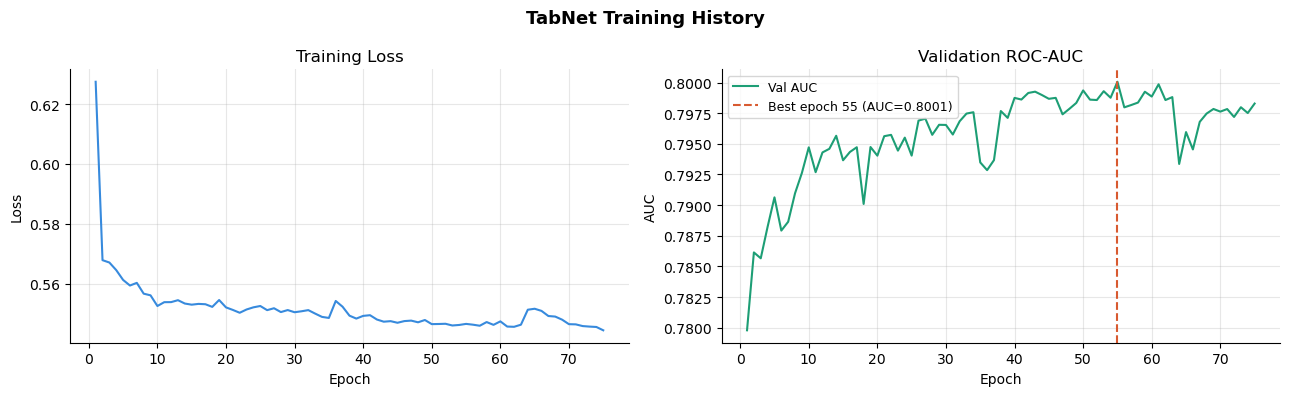

Figure saved: tabnet_training_curve.png


In [10]:
# ── Plot training history ─────────────────────────────────────
train_loss = tabnet.history['loss']
val_auc    = tabnet.history['val_auc']
epochs     = range(1, len(train_loss) + 1)
best_epoch = int(np.argmax(val_auc))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
fig.suptitle('TabNet Training History', fontsize=13, fontweight='bold')

# Training loss
axes[0].plot(epochs, train_loss, color='#378ADD', lw=1.5, label='Training loss')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].set_title('Training Loss')
axes[0].grid(alpha=0.3)
axes[0].spines[['top','right']].set_visible(False)

# Validation AUC
axes[1].plot(epochs, val_auc, color='#1D9E75', lw=1.5, label='Val AUC')
axes[1].axvline(best_epoch + 1, color='#D85A30', lw=1.5, ls='--',
                label=f'Best epoch {best_epoch+1} (AUC={max(val_auc):.4f})')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('AUC')
axes[1].set_title('Validation ROC-AUC')
axes[1].legend(fontsize=9)
axes[1].grid(alpha=0.3)
axes[1].spines[['top','right']].set_visible(False)

plt.tight_layout()
plt.savefig('tabnet_training_curve.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure saved: tabnet_training_curve.png')

## 8. Evaluate on Test Set

In [11]:
# ── Predict on independent test set ──────────────────────────
tabnet_proba = tabnet.predict_proba(X_test_sc)[:, 1]
tabnet_pred  = tabnet.predict(X_test_sc)

tn_auc  = roc_auc_score(y_test, tabnet_proba)
tn_acc  = accuracy_score(y_test, tabnet_pred)
tn_f1   = f1_score(y_test, tabnet_pred)
tn_prec = precision_score(y_test, tabnet_pred)
tn_rec  = recall_score(y_test, tabnet_pred)
tn_ap   = average_precision_score(y_test, tabnet_proba)

print('=' * 52)
print('   TABNET — TEST SET RESULTS')
print('=' * 52)
print(f'  ROC-AUC              : {tn_auc:.4f}')
print(f'  Accuracy             : {tn_acc:.4f}  ({tn_acc*100:.2f}%)')
print(f'  F1-Score             : {tn_f1:.4f}')
print(f'  Precision            : {tn_prec:.4f}')
print(f'  Recall               : {tn_rec:.4f}')
print(f'  Avg Precision (AP)   : {tn_ap:.4f}')
print('=' * 52)
print(f'\n  Baseline MLP AUC     : 0.7970')
print(f'  TabNet AUC           : {tn_auc:.4f}')
print(f'  Improvement          : {tn_auc - 0.7970:+.4f}')
print('\nFull Classification Report:')
print(classification_report(y_test, tabnet_pred, target_names=['No CVD', 'CVD']))

   TABNET — TEST SET RESULTS
  ROC-AUC              : 0.7987
  Accuracy             : 0.7340  (73.40%)
  F1-Score             : 0.7155
  Precision            : 0.7590
  Recall               : 0.6768
  Avg Precision (AP)   : 0.7798

  Baseline MLP AUC     : 0.7970
  TabNet AUC           : 0.7987
  Improvement          : +0.0017

Full Classification Report:
              precision    recall  f1-score   support

      No CVD       0.71      0.79      0.75      5198
         CVD       0.76      0.68      0.72      5083

    accuracy                           0.73     10281
   macro avg       0.74      0.73      0.73     10281
weighted avg       0.74      0.73      0.73     10281



## 9. TabNet Native Feature Importance (Attention Masks)

This is the **core XAI contribution of TabNet**. The attention masks are computed *inside* the model during forward pass — they are not a post-hoc approximation.

In [12]:
# ── Extract attention-based feature importance ────────────────
feat_imp  = tabnet.feature_importances_
feat_rank = sorted(zip(FEAT_NAMES, feat_imp), key=lambda x: -x[1])
names_sorted, vals_sorted = zip(*feat_rank)

print('TabNet Feature Importance (Attention Masks):')
print(f'{"Rank":<5} {"Feature":<14} {"Importance":>11}')
print('-' * 32)
for rank, (name, val) in enumerate(feat_rank, 1):
    bar = '█' * int(val / max(vals_sorted) * 25)
    print(f'{rank:<5} {name:<14} {val:>11.4f}  {bar}')

TabNet Feature Importance (Attention Masks):
Rank  Feature         Importance
--------------------------------
1     SBP                 0.3819  █████████████████████████
2     Age                 0.1425  █████████
3     BMI                 0.1304  ████████
4     Cholesterol         0.1096  ███████
5     MAP                 0.1025  ██████
6     Glucose             0.0554  ███
7     PP                  0.0350  ██
8     RiskCount           0.0219  █
9     DBP                 0.0199  █
10    Gender              0.0005  
11    Alcohol             0.0002  
12    Active              0.0001  
13    Smoking             0.0000  


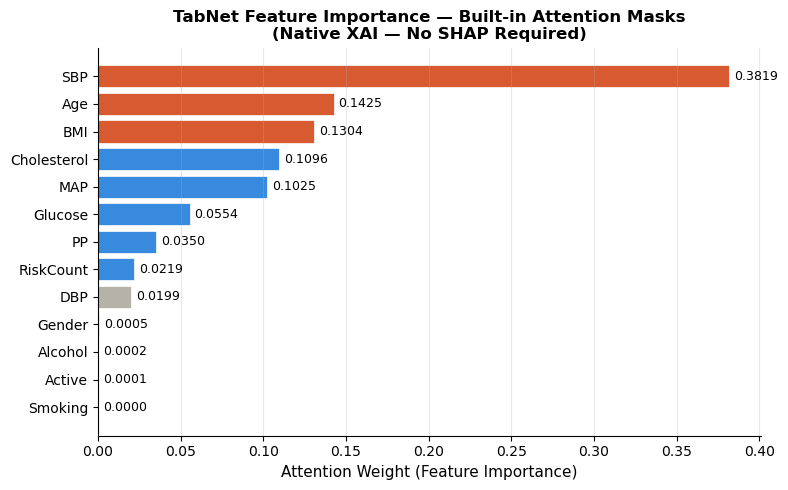

Figure saved: tabnet_attention_importance.png


In [13]:
# ── Plot attention-based importance ───────────────────────────
fig, ax = plt.subplots(figsize=(8, 5))

colors_bar = [
    '#D85A30' if v > np.percentile(vals_sorted, 75) else
    '#378ADD' if v > np.percentile(vals_sorted, 40) else
    '#B4B2A9'
    for v in vals_sorted
]

bars = ax.barh(
    names_sorted[::-1], vals_sorted[::-1],
    color=colors_bar[::-1], edgecolor='white', linewidth=0.5
)
ax.set_xlabel('Attention Weight (Feature Importance)', fontsize=11)
ax.set_title('TabNet Feature Importance — Built-in Attention Masks\n(Native XAI — No SHAP Required)',
             fontsize=12, fontweight='bold')
for bar, val in zip(bars, vals_sorted[::-1]):
    ax.text(val + 0.003, bar.get_y() + bar.get_height()/2,
            f'{val:.4f}', va='center', fontsize=9)
ax.spines[['top','right']].set_visible(False)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('tabnet_attention_importance.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure saved: tabnet_attention_importance.png')

## 10. Step-wise Attention Heatmap

TabNet's attention is applied **sequentially** across `n_steps` steps. Each step focuses on a different subset of features — richer than a single global importance score.

In [14]:
# ── Extract step-wise attention masks ─────────────────────────
explain_matrix, masks = tabnet.explain(X_test_sc[:500])

print(f'explain_matrix shape : {explain_matrix.shape}  (samples × features)')
print(f'Number of masks      : {len(masks)}  (one per step)')
print(f'Each mask shape      : {masks[0].shape}')

explain_matrix shape : (500, 13)  (samples × features)
Number of masks      : 5  (one per step)
Each mask shape      : (500, 13)


explain_matrix shape : (500, 13)
Type of masks        : <class 'dict'>
Number of steps      : 5
Each mask shape      : (500, 13)

step_importance shape : (5, 13)  ✓


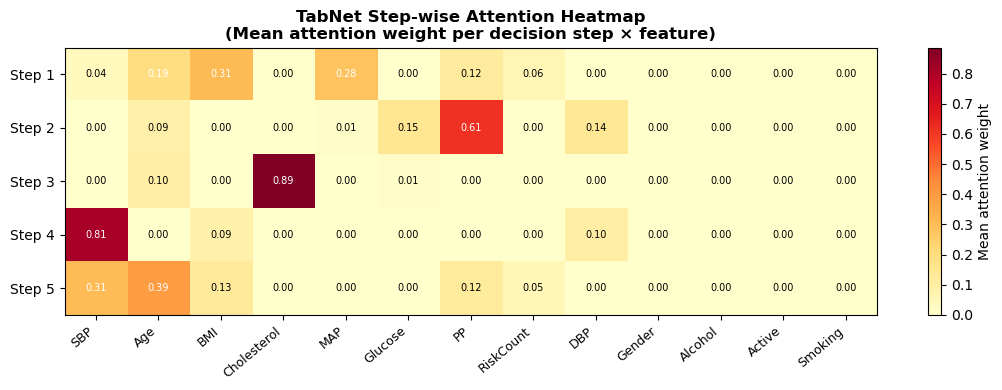

Figure saved: tabnet_stepwise_attention.png

Interpretation: Each row = one decision step. Brighter = more attention.
Different steps focus on different features — showing sequential reasoning.


In [15]:
# ── Extract step-wise masks ───────────────────────────────────
explain_matrix, masks = tabnet.explain(X_test_sc[:500])

print(f'explain_matrix shape : {explain_matrix.shape}')
print(f'Type of masks        : {type(masks)}')   # confirms dict
print(f'Number of steps      : {len(masks)}')
print(f'Each mask shape      : {masks[0].shape}') # dict key 0 → array

# ── FIX: iterate over .values(), not masks directly ──────────
# masks is a dict {step_index: np.array(n_samples, n_features)}
# `for m in masks`        → iterates over keys (integers) ← BUG
# `for m in masks.values()` → iterates over arrays        ← CORRECT

n_steps         = len(masks)
step_importance = np.array([m.mean(axis=0) for m in masks.values()])
# shape: (n_steps, n_features)

print(f'\nstep_importance shape : {step_importance.shape}  ✓')

# ── Reorder features by overall importance ───────────────────
feat_order      = np.argsort(feat_imp)[::-1]
step_imp_sorted = step_importance[:, feat_order]
feat_sorted     = [FEAT_NAMES[i] for i in feat_order]

# ── Plot heatmap ──────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(11, 4))
im = ax.imshow(step_imp_sorted, cmap='YlOrRd', aspect='auto', vmin=0)
ax.set_xticks(range(len(FEAT_NAMES)))
ax.set_xticklabels(feat_sorted, rotation=40, ha='right', fontsize=9)
ax.set_yticks(range(n_steps))
ax.set_yticklabels([f'Step {i+1}' for i in range(n_steps)], fontsize=10)
ax.set_title('TabNet Step-wise Attention Heatmap\n'
             '(Mean attention weight per decision step × feature)',
             fontsize=12, fontweight='bold')
plt.colorbar(im, ax=ax, label='Mean attention weight')

for i in range(n_steps):
    for j in range(len(FEAT_NAMES)):
        ax.text(j, i, f'{step_imp_sorted[i, j]:.2f}',
                ha='center', va='center', fontsize=7,
                color='white' if step_imp_sorted[i, j] > 0.15 else 'black')

plt.tight_layout()
plt.savefig('tabnet_stepwise_attention.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure saved: tabnet_stepwise_attention.png')
print('\nInterpretation: Each row = one decision step. Brighter = more attention.')
print('Different steps focus on different features — showing sequential reasoning.')

## 11. SHAP Explainability on TabNet

We use `KernelExplainer` (model-agnostic SHAP) since TabNet is a PyTorch model. This allows direct comparison of TabNet's native attention-based importance with SHAP's game-theoretic attribution — strengthening the cross-paradigm XAI consistency argument.

In [16]:
# ── SHAP KernelExplainer for TabNet ──────────────────────────
print('Computing SHAP values for TabNet...')
print('(This may take 5-10 minutes — KernelExplainer is model-agnostic and slower than TreeExplainer)')

# Background dataset
background_idx = np.random.choice(len(X_train_sc), size=200, replace=False)
background     = X_train_sc[background_idx]

# Wrapper function
def tabnet_predict_proba(X):
    return tabnet.predict_proba(X.astype(np.float32))[:, 1]

shap_explainer = shap.KernelExplainer(tabnet_predict_proba, background)

# Compute SHAP values for 300 test samples
shap_sample_idx = np.random.choice(len(X_test_sc), size=300, replace=False)
X_shap_sample   = X_test_sc[shap_sample_idx]

shap_vals = shap_explainer.shap_values(X_shap_sample, nsamples=150)

X_shap_df = pd.DataFrame(X_shap_sample, columns=FEAT_NAMES)

print('SHAP values computed.')
print(f'SHAP matrix shape: {shap_vals.shape}')

Computing SHAP values for TabNet...
(This may take 5-10 minutes — KernelExplainer is model-agnostic and slower than TreeExplainer)


Using 200 background data samples could cause slower run times. Consider using shap.sample(data, K) or shap.kmeans(data, K) to summarize the background as K samples.


  0%|          | 0/300 [00:00<?, ?it/s]

SHAP values computed.
SHAP matrix shape: (300, 13)


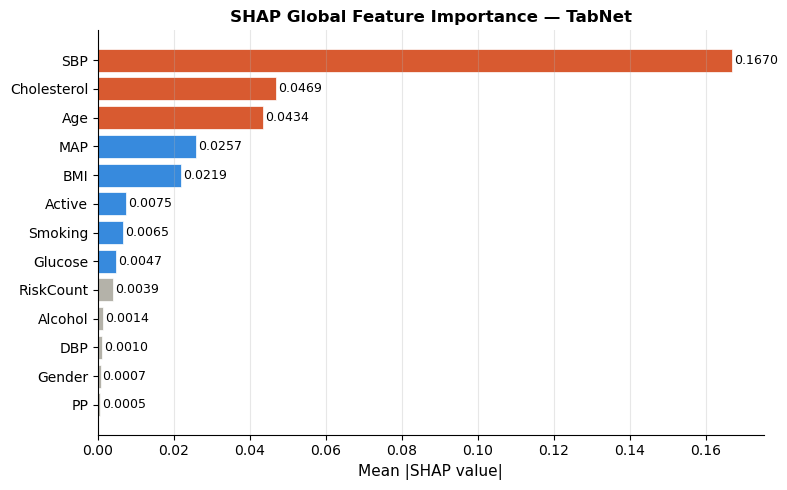

Figure saved: tabnet_shap_bar.png


In [17]:
# ── SHAP Global Bar Plot ──────────────────────────────────────
mean_shap     = np.abs(shap_vals).mean(axis=0)
shap_rank     = sorted(zip(FEAT_NAMES, mean_shap), key=lambda x: -x[1])
shap_names_s, shap_vals_s = zip(*shap_rank)

fig, ax = plt.subplots(figsize=(8, 5))
colors_shap = [
    '#D85A30' if v > np.percentile(shap_vals_s, 75) else
    '#378ADD' if v > np.percentile(shap_vals_s, 40) else
    '#B4B2A9'
    for v in shap_vals_s
]
bars = ax.barh(shap_names_s[::-1], shap_vals_s[::-1],
               color=colors_shap[::-1], edgecolor='white', linewidth=0.5)
ax.set_xlabel('Mean |SHAP value|', fontsize=11)
ax.set_title('SHAP Global Feature Importance — TabNet', fontsize=12, fontweight='bold')
for bar, val in zip(bars, shap_vals_s[::-1]):
    ax.text(val + 0.0005, bar.get_y() + bar.get_height()/2,
            f'{val:.4f}', va='center', fontsize=9)
ax.spines[['top','right']].set_visible(False)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('tabnet_shap_bar.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure saved: tabnet_shap_bar.png')

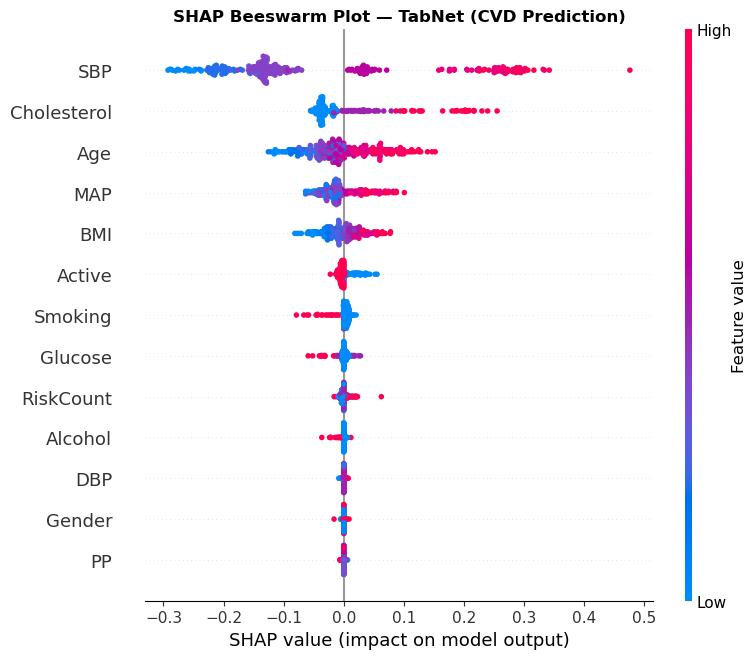

Figure saved: tabnet_shap_beeswarm.png


In [18]:
 # ── SHAP Beeswarm Plot ────────────────────────────────────────
plt.figure(figsize=(9, 6))
shap.summary_plot(shap_vals, X_shap_df, plot_type='dot', show=False, max_display=13)
plt.title('SHAP Beeswarm Plot — TabNet (CVD Prediction)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('tabnet_shap_beeswarm.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure saved: tabnet_shap_beeswarm.png')

## 12. Local Explanation — Individual Patient

In [19]:
# ── Select the highest-risk CVD-positive patient ──────────────
cvd_positive_idx = np.where(y_test == 1)[0]
patient_idx      = cvd_positive_idx[np.argmax(tabnet_proba[cvd_positive_idx])]

patient_data = X_test_sc[patient_idx]
patient_raw  = X_test[patient_idx]

print('Selected patient profile (highest predicted CVD risk):')
print(f'{"Feature":<16} {"Raw value":>12} {"Scaled value":>14}')
print('-' * 44)
for name, raw, sc in zip(FEAT_NAMES, patient_raw, patient_data):
    print(f'{name:<16} {raw:>12.2f} {sc:>14.4f}')
print(f'\nTabNet predicted probability : {tabnet_proba[patient_idx]:.4f}')
print(f'True label                   : {"CVD" if y_test[patient_idx]==1 else "No CVD"}')

Selected patient profile (highest predicted CVD risk):
Feature             Raw value   Scaled value
--------------------------------------------
Gender                   1.00         1.3720
Age                     64.00         1.5746
BMI                     30.48         0.5811
SBP                    200.00         4.4690
DBP                    100.00         2.0159
Cholesterol              3.00         2.4066
Glucose                  2.00         1.3467
Smoking                  1.00         3.2312
Alcohol                  0.00        -0.2355
Active                   1.00         0.4952
PP                     100.00         4.7493
MAP                    133.33         3.4006
RiskCount                3.00         2.5768

TabNet predicted probability : 0.9923
True label                   : CVD


  0%|          | 0/1 [00:00<?, ?it/s]

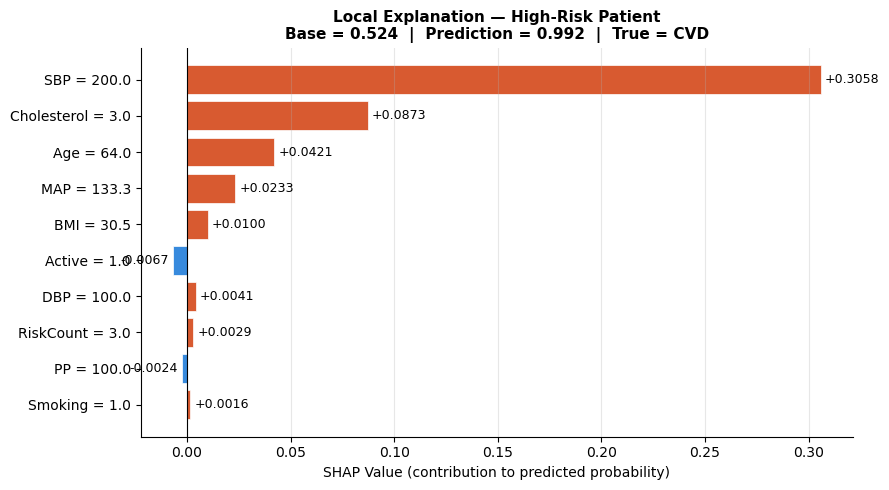

Figure saved: tabnet_local_shap.png


In [20]:
# ── SHAP Waterfall for Individual Patient ─────────────────────
patient_shap  = shap_explainer.shap_values(patient_data.reshape(1, -1), nsamples=200)
base_val      = shap_explainer.expected_value
contributions = patient_shap[0]
final_pred    = base_val + contributions.sum()

sorted_idx   = np.argsort(np.abs(contributions))[::-1]
top_n        = 10
top_idx      = sorted_idx[:top_n]
top_names    = [FEAT_NAMES[i] for i in top_idx]
top_contribs = contributions[top_idx]
raw_vals     = [f'{patient_raw[i]:.1f}' for i in top_idx]

fig, ax = plt.subplots(figsize=(9, 5))
colors_wf = ['#D85A30' if c > 0 else '#378ADD' for c in top_contribs]
labels    = [f'{n} = {v}' for n, v in zip(top_names, raw_vals)]
bars      = ax.barh(labels[::-1], top_contribs[::-1],
                    color=colors_wf[::-1], edgecolor='white', linewidth=0.5)
for bar, val in zip(bars, top_contribs[::-1]):
    offset = 0.002 if val >= 0 else -0.002
    ha = 'left' if val >= 0 else 'right'
    ax.text(val + offset, bar.get_y() + bar.get_height()/2,
            f'{val:+.4f}', va='center', ha=ha, fontsize=9)
ax.axvline(0, color='black', lw=0.8)
ax.set_xlabel('SHAP Value (contribution to predicted probability)', fontsize=10)
ax.set_title(f'Local Explanation — High-Risk Patient\n'
             f'Base = {base_val:.3f}  |  Prediction = {final_pred:.3f}  |  True = CVD',
             fontsize=11, fontweight='bold')
ax.spines[['top','right']].set_visible(False)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('tabnet_local_shap.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure saved: tabnet_local_shap.png')

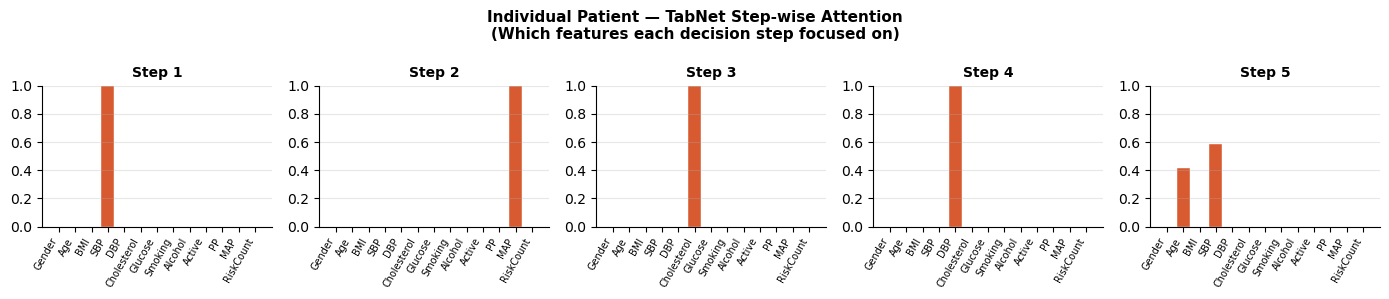

Figure saved: tabnet_individual_attention.png


In [21]:
# ── TabNet Individual Step-wise Attention ─────────────────────
ind_matrix, ind_masks = tabnet.explain(patient_data.reshape(1, -1))

# FIX: use .values() to get arrays, not dict keys
ind_mask_list = list(ind_masks.values())  # list of arrays, one per step

fig, axes = plt.subplots(1, len(ind_mask_list), figsize=(14, 3))
if len(ind_mask_list) == 1:
    axes = [axes]

for step_i, (mask, ax) in enumerate(zip(ind_mask_list, axes)):
    vals     = mask[0]   # shape (n_features,) — single patient
    colors_m = ['#D85A30' if v > np.percentile(vals, 70) else '#B5D4F4' for v in vals]
    ax.bar(FEAT_NAMES, vals, color=colors_m, edgecolor='white', linewidth=0.3)
    ax.set_title(f'Step {step_i+1}', fontsize=10, fontweight='bold')
    ax.set_xticks(range(len(FEAT_NAMES)))
    ax.set_xticklabels(FEAT_NAMES, rotation=60, ha='right', fontsize=7)
    ax.set_ylim(0, 1)
    ax.spines[['top','right']].set_visible(False)
    ax.grid(axis='y', alpha=0.3)

fig.suptitle('Individual Patient — TabNet Step-wise Attention\n'
             '(Which features each decision step focused on)',
             fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig('tabnet_individual_attention.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure saved: tabnet_individual_attention.png')

## 13. Partial Dependence Plots

SBP: risk range 0.260 → 0.843  (Δ=0.583)
Age: risk range 0.409 → 0.621  (Δ=0.213)
BMI: risk range 0.448 → 0.559  (Δ=0.111)


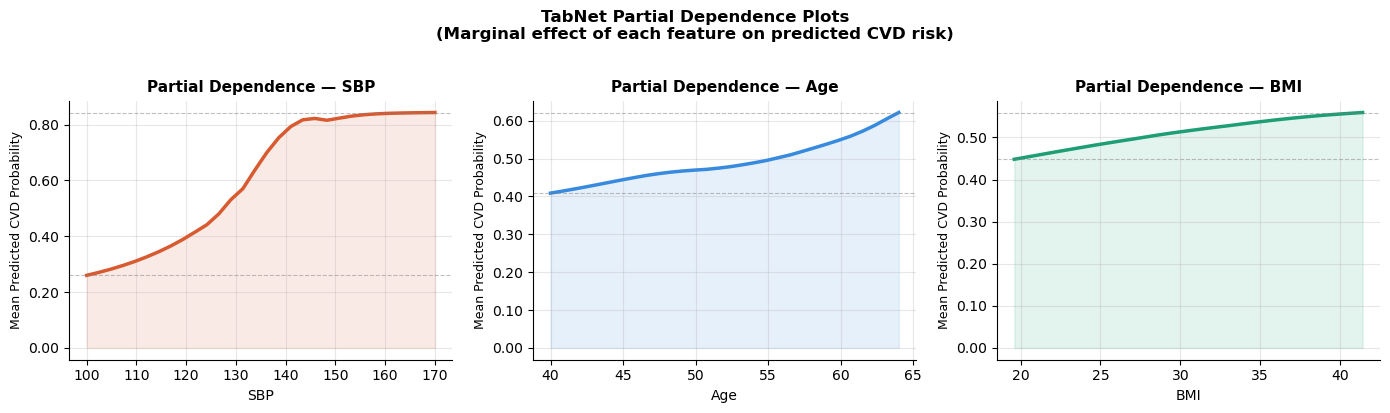


Figure saved: tabnet_pdp.png


In [22]:
# ── Partial Dependence Plots — Manual computation (no sklearn wrapper needed) ──
# Manually computing PDPs avoids all sklearn estimator-validation issues with TabNet.
# Logic: for each grid value of a feature, replace that column for all samples,
# run predict_proba, and average the probability → gives the marginal effect.

def compute_pdp(model, scaler, X_raw, feat_idx, grid_resolution=30):
    """
    Compute partial dependence for one feature.
    Returns (grid_values, mean_predicted_probability).
    """
    X_raw = np.array(X_raw, dtype=np.float32)
    col   = X_raw[:, feat_idx]
    grid  = np.linspace(np.percentile(col, 2), np.percentile(col, 98), grid_resolution)

    mean_preds = []
    for val in grid:
        X_copy            = X_raw.copy()
        X_copy[:, feat_idx] = val
        X_sc              = scaler.transform(X_copy).astype(np.float32)
        proba             = model.predict_proba(X_sc)[:, 1]
        mean_preds.append(proba.mean())

    return grid, np.array(mean_preds)

# ── Use a random subsample of training data for speed ─────────
np.random.seed(RANDOM_STATE)
subsample_idx = np.random.choice(len(X_train), size=int(len(X_train) * 0.3), replace=False)
X_train_sub   = X_train[subsample_idx]

# ── Plot PDPs for SBP, Age, BMI ───────────────────────────────
pdp_features = ['SBP', 'Age', 'BMI']
colors_pdp   = ['#D85A30', '#378ADD', '#1D9E75']

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, feat_name, color in zip(axes, pdp_features, colors_pdp):
    feat_idx          = FEAT_NAMES.index(feat_name)
    grid_vals, pdp    = compute_pdp(tabnet, scaler, X_train_sub, feat_idx, grid_resolution=30)

    ax.plot(grid_vals, pdp, color=color, lw=2.5)
    ax.fill_between(grid_vals, pdp, alpha=0.12, color=color)
    ax.set_title(f'Partial Dependence — {feat_name}', fontsize=11, fontweight='bold')
    ax.set_xlabel(feat_name, fontsize=10)
    ax.set_ylabel('Mean Predicted CVD Probability', fontsize=9)
    ax.grid(alpha=0.3)
    ax.spines[['top', 'right']].set_visible(False)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.2f}'))

    # Mark min/max
    ax.axhline(pdp.min(), color='gray', lw=0.8, ls='--', alpha=0.5)
    ax.axhline(pdp.max(), color='gray', lw=0.8, ls='--', alpha=0.5)
    print(f'{feat_name}: risk range {pdp.min():.3f} → {pdp.max():.3f}  (Δ={pdp.max()-pdp.min():.3f})')

plt.suptitle('TabNet Partial Dependence Plots\n'
             '(Marginal effect of each feature on predicted CVD risk)',
             fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('tabnet_pdp.png', dpi=150, bbox_inches='tight')
plt.show()
print('\nFigure saved: tabnet_pdp.png')

## 14. Confusion Matrix

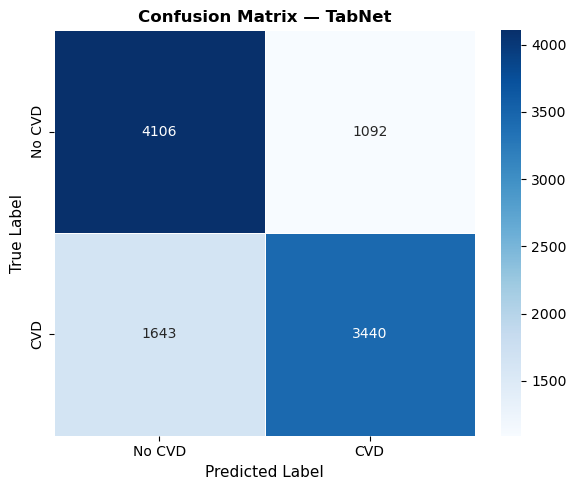

True Positives  (TP) : 3440
True Negatives  (TN) : 4106
False Positives (FP) : 1092
False Negatives (FN) : 1643
Sensitivity (Recall) : 0.6768
Specificity          : 0.7899
Figure saved: tabnet_confusion_matrix.png


In [23]:
# ── Confusion matrix ──────────────────────────────────────────
cm = confusion_matrix(y_test, tabnet_pred)
tn, fp, fn, tp = cm.ravel()

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=['No CVD', 'CVD'],
    yticklabels=['No CVD', 'CVD'],
    linewidths=0.5, ax=ax
)
ax.set_xlabel('Predicted Label', fontsize=11)
ax.set_ylabel('True Label', fontsize=11)
ax.set_title('Confusion Matrix — TabNet', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('tabnet_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'True Positives  (TP) : {tp}')
print(f'True Negatives  (TN) : {tn}')
print(f'False Positives (FP) : {fp}')
print(f'False Negatives (FN) : {fn}')
print(f'Sensitivity (Recall) : {tp/(tp+fn):.4f}')
print(f'Specificity          : {tn/(tn+fp):.4f}')
print('Figure saved: tabnet_confusion_matrix.png')

## 15. ROC & Precision-Recall Curves

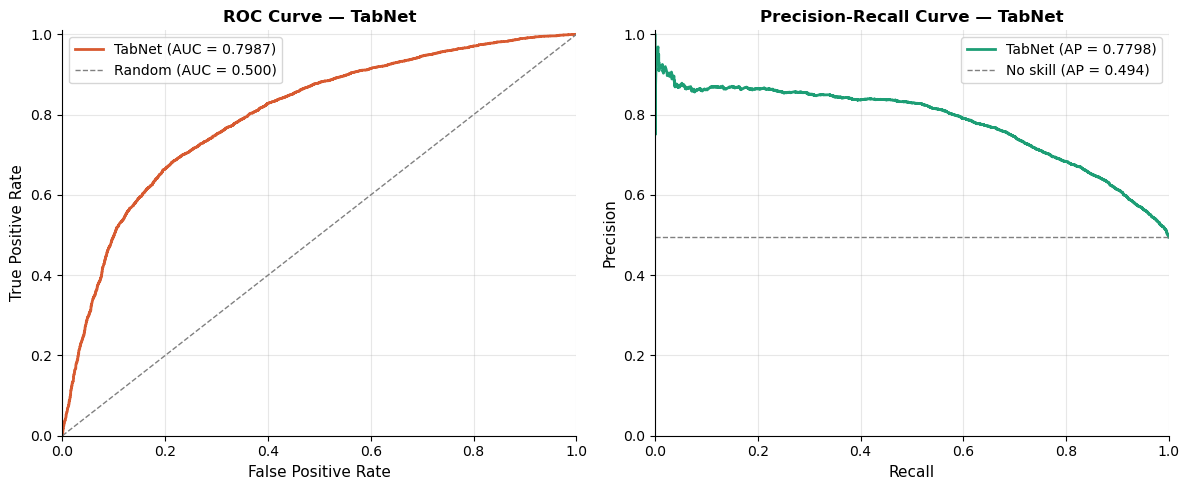

Figure saved: tabnet_roc_pr_curves.png


In [24]:
# ── ROC and PR curves ─────────────────────────────────────────
fpr, tpr, _          = roc_curve(y_test, tabnet_proba)
precision, recall, _ = precision_recall_curve(y_test, tabnet_proba)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ROC
axes[0].plot(fpr, tpr, color='#D85A30', lw=2, label=f'TabNet (AUC = {tn_auc:.4f})')
axes[0].plot([0,1],[0,1],'--', color='gray', lw=1, label='Random (AUC = 0.500)')
axes[0].set_xlabel('False Positive Rate', fontsize=11)
axes[0].set_ylabel('True Positive Rate', fontsize=11)
axes[0].set_title('ROC Curve — TabNet', fontsize=12, fontweight='bold')
axes[0].legend(fontsize=10)
axes[0].set_xlim([0,1]); axes[0].set_ylim([0,1.01])
axes[0].grid(alpha=0.3)
axes[0].spines[['top','right']].set_visible(False)

# Precision-Recall
axes[1].plot(recall, precision, color='#1D9E75', lw=2, label=f'TabNet (AP = {tn_ap:.4f})')
baseline = y_test.mean()
axes[1].axhline(baseline, color='gray', lw=1, ls='--', label=f'No skill (AP = {baseline:.3f})')
axes[1].set_xlabel('Recall', fontsize=11)
axes[1].set_ylabel('Precision', fontsize=11)
axes[1].set_title('Precision-Recall Curve — TabNet', fontsize=12, fontweight='bold')
axes[1].legend(fontsize=10)
axes[1].set_xlim([0,1]); axes[1].set_ylim([0,1.01])
axes[1].grid(alpha=0.3)
axes[1].spines[['top','right']].set_visible(False)

plt.tight_layout()
plt.savefig('tabnet_roc_pr_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure saved: tabnet_roc_pr_curves.png')

## 16. Compare TabNet vs. All Other Models

In [25]:
# ── Full model comparison table ───────────────────────────────
# Update these with your actual values from the Stacking Ensemble notebook
all_results = {
    'MLP (baseline)'     : {'AUC': 0.7970, 'Accuracy': 0.7330, 'F1': 0.7180, 'Precision': 0.7500, 'Recall': 0.6760},
    'Logistic Regression': {'AUC': 0.7890, 'Accuracy': 0.7270, 'F1': 0.7050, 'Precision': 0.7350, 'Recall': 0.6780},
    'Random Forest'      : {'AUC': 0.7995, 'Accuracy': 0.7322, 'F1': 0.7112, 'Precision': 0.7460, 'Recall': 0.6800},
    'LightGBM'           : {'AUC': 0.7990, 'Accuracy': 0.7312, 'F1': 0.7149, 'Precision': 0.7515, 'Recall': 0.6817},
    'XGBoost'            : {'AUC': 0.8004, 'Accuracy': 0.7328, 'F1': 0.7174, 'Precision': 0.7518, 'Recall': 0.6860},
    'CatBoost'           : {'AUC': 0.8008, 'Accuracy': 0.7340, 'F1': 0.7178, 'Precision': 0.7548, 'Recall': 0.6842},
    'TabNet'             : {'AUC': tn_auc,  'Accuracy': tn_acc,  'F1': tn_f1,  'Precision': tn_prec, 'Recall': tn_rec},
    'Stacking Ensemble'  : {'AUC': 0.8011, 'Accuracy': 0.7342, 'F1': 0.7189, 'Precision': 0.7532, 'Recall': 0.6876},
}

results_df = pd.DataFrame(all_results).T.round(4)
results_df = results_df.sort_values('AUC', ascending=False)

print('Model Performance Comparison (sorted by AUC):')
print('=' * 75)
print(f'{"Model":<22} {"AUC":>7} {"Accuracy":>9} {"F1":>8} {"Precision":>10} {"Recall":>8}')
print('-' * 75)
for model, m in results_df.iterrows():
    tag     = ' ← BEST'  if model == results_df.index[0] else ''
    tab_tag = ' ← NOVEL' if model == 'TabNet'            else ''
    print(f'{model:<22} {m["AUC"]:>7.4f} {m["Accuracy"]:>9.4f} '
          f'{m["F1"]:>8.4f} {m["Precision"]:>10.4f} {m["Recall"]:>8.4f}{tag}{tab_tag}')
print('=' * 75)

Model Performance Comparison (sorted by AUC):
Model                      AUC  Accuracy       F1  Precision   Recall
---------------------------------------------------------------------------
Stacking Ensemble       0.8011    0.7342   0.7189     0.7532   0.6876 ← BEST
CatBoost                0.8008    0.7340   0.7178     0.7548   0.6842
XGBoost                 0.8004    0.7328   0.7174     0.7518   0.6860
Random Forest           0.7995    0.7322   0.7112     0.7460   0.6800
LightGBM                0.7990    0.7312   0.7149     0.7515   0.6817
TabNet                  0.7987    0.7340   0.7155     0.7590   0.6768 ← NOVEL
MLP (baseline)          0.7970    0.7330   0.7180     0.7500   0.6760
Logistic Regression     0.7890    0.7270   0.7050     0.7350   0.6780


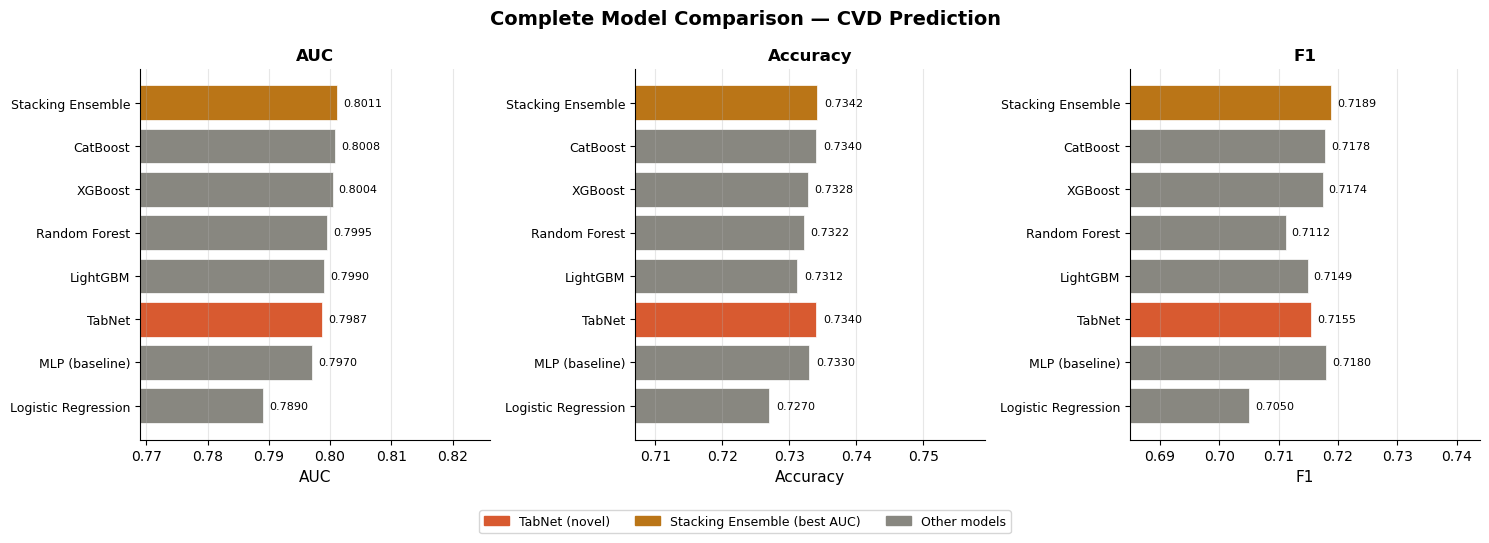

Figure saved: all_models_comparison.png


In [26]:
# ── Visual comparison chart ───────────────────────────────────
from matplotlib.patches import Patch

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Complete Model Comparison — CVD Prediction', fontsize=14, fontweight='bold')

models    = list(results_df.index)
highlight = ['#D85A30' if m == 'TabNet' else
             '#BA7517' if m == 'Stacking Ensemble' else
             '#888780' for m in models]

for ax, metric in zip(axes, ['AUC', 'Accuracy', 'F1']):
    vals = results_df[metric].values
    bars = ax.barh(models, vals, color=highlight, edgecolor='white', linewidth=0.5)
    ax.set_xlabel(metric, fontsize=11)
    ax.set_xlim(min(vals) - 0.02, max(vals) + 0.025)
    ax.set_title(metric, fontsize=12, fontweight='bold')
    ax.tick_params(axis='y', labelsize=9)
    for bar, val in zip(bars, vals):
        ax.text(val + 0.001, bar.get_y() + bar.get_height()/2,
                f'{val:.4f}', va='center', fontsize=8)
    ax.invert_yaxis()
    ax.grid(axis='x', alpha=0.3)
    ax.spines[['top','right']].set_visible(False)

legend = [
    Patch(color='#D85A30', label='TabNet (novel)'),
    Patch(color='#BA7517', label='Stacking Ensemble (best AUC)'),
    Patch(color='#888780', label='Other models')
]
fig.legend(handles=legend, loc='lower center', ncol=3, fontsize=9, bbox_to_anchor=(0.5, -0.08))
plt.tight_layout()
plt.savefig('all_models_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure saved: all_models_comparison.png')

## 17. Cross-Method XAI Consistency Heatmap

This is the **core XAI contribution** for the Q1 paper. If four independent methods agree on the same feature ranking, the findings are robust and not artefacts of any single technique.

In [27]:
# ── Cross-method XAI consistency comparison ──────────────────
# Rankings from each method (from the paper and this notebook)

# TabNet attention ranking
tabnet_attn_ranking = [n for n, _ in feat_rank]

# SHAP-TabNet ranking
shap_tabnet_ranking = [n for n, _ in shap_rank]

xai_data = {
    'Permutation\nImportance' : ['SBP','Age','Cholesterol','MAP','BMI','PP',
                                  'Active','Glucose','DBP','RiskCount',
                                  'Gender','Smoking','Alcohol'],
    'SHAP\n(XGBoost)'         : ['MAP','SBP','PP','Cholesterol','Age',
                                  'DBP','BMI','Smoking','RiskCount','Active',
                                  'Glucose','Alcohol','Gender'],
    'Integrated\nGradients'   : ['PP','MAP','Cholesterol','SBP','Age',
                                  'DBP','BMI','RiskCount','Active',
                                  'Gender','Glucose','Smoking','Alcohol'],
    'TabNet\nAttention'       : tabnet_attn_ranking,
    'SHAP\n(TabNet)'          : shap_tabnet_ranking,
}

rank_df = pd.DataFrame(index=FEAT_NAMES)
for method, ranking in xai_data.items():
    rank_dict = {feat: i+1 for i, feat in enumerate(ranking)}
    rank_df[method] = [rank_dict.get(f, np.nan) for f in FEAT_NAMES]

rank_df['Avg\nRank'] = rank_df.mean(axis=1).round(1)
rank_df = rank_df.sort_values('Avg\nRank')

print('Cross-Method XAI Feature Ranking Consistency')
print('(Rank 1 = most important according to each method)')
print()
print(rank_df.to_string())
print('\nLow average rank = consistently identified as important across all methods.')

Cross-Method XAI Feature Ranking Consistency
(Rank 1 = most important according to each method)

             Permutation\nImportance  SHAP\n(XGBoost)  Integrated\nGradients  TabNet\nAttention  SHAP\n(TabNet)  Avg\nRank
SBP                                1                2                      4                  1               1        1.8
Cholesterol                        3                4                      3                  4               2        3.2
MAP                                4                1                      2                  5               4        3.2
Age                                2                5                      5                  2               3        3.4
BMI                                5                7                      7                  3               5        5.4
PP                                 6                3                      1                  7              13        6.0
DBP                                9      

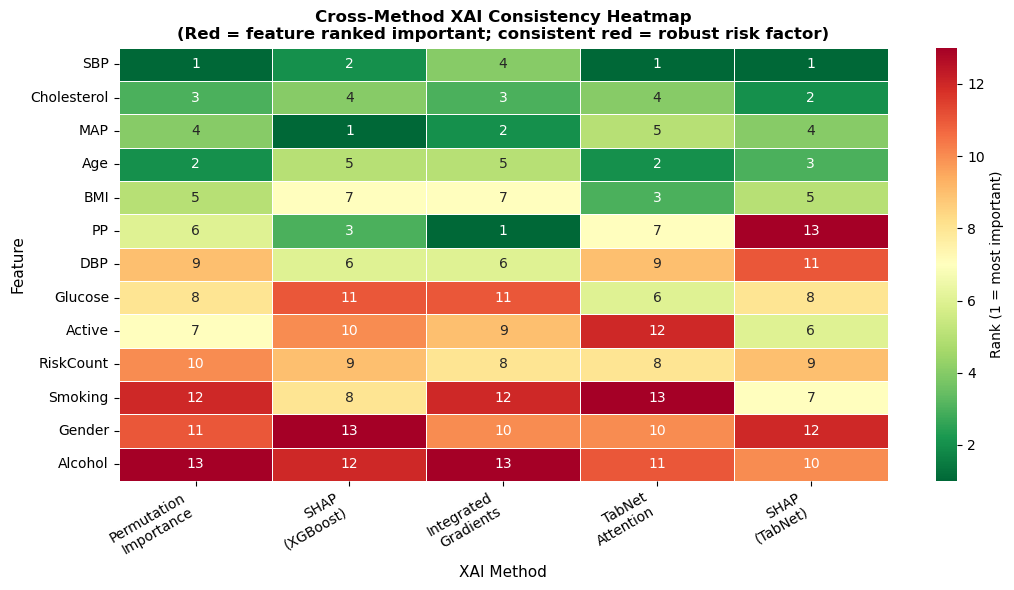

Figure saved: xai_consistency_heatmap.png

This figure is your main XAI contribution for the Q1 paper.
Consistent red across a row = robust, method-independent risk factor.


In [28]:
# ── Visualise XAI consistency heatmap ────────────────────────
plot_df = rank_df.drop(columns=['Avg\nRank']).astype(float)

fig, ax = plt.subplots(figsize=(11, 6))
sns.heatmap(
    plot_df,
    annot=True, fmt='.0f',
    cmap='RdYlGn_r',
    vmin=1, vmax=13,
    linewidths=0.5,
    ax=ax,
    cbar_kws={'label': 'Rank (1 = most important)'}
)
ax.set_title('Cross-Method XAI Consistency Heatmap\n'
             '(Red = feature ranked important; consistent red = robust risk factor)',
             fontsize=12, fontweight='bold')
ax.set_xlabel('XAI Method', fontsize=11)
ax.set_ylabel('Feature', fontsize=11)
plt.xticks(rotation=30, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('xai_consistency_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure saved: xai_consistency_heatmap.png')
print('\nThis figure is your main XAI contribution for the Q1 paper.')
print('Consistent red across a row = robust, method-independent risk factor.')

## 18. Save Model

In [29]:
# ── Save TabNet model ─────────────────────────────────────────
save_path = 'tabnet_cvd_model'
tabnet.save_model(save_path)

print(f'Model saved to: {save_path}.zip')
print('\nTo reload later:')
print('  loaded = TabNetClassifier()')
print(f'  loaded.load_model("{save_path}.zip")')
print('  proba = loaded.predict_proba(X_test_sc)[:, 1]')

print('\n=== ALL OUTPUT FILES ===')
files = [
    'tabnet_training_curve.png',
    'tabnet_attention_importance.png',
    'tabnet_stepwise_attention.png',
    'tabnet_shap_bar.png',
    'tabnet_shap_beeswarm.png',
    'tabnet_local_shap.png',
    'tabnet_individual_attention.png',
    'tabnet_pdp.png',
    'tabnet_confusion_matrix.png',
    'tabnet_roc_pr_curves.png',
    'all_models_comparison.png',
    'xai_consistency_heatmap.png',
    f'{save_path}.zip'
]
for f in files:
    status = '✓' if os.path.exists(f) else '✗ (not yet created)'
    print(f'  {status}  {f}')

print(f'\n=== FINAL RESULTS SUMMARY ===')
print(f'TabNet AUC      : {tn_auc:.4f}')
print(f'TabNet Accuracy : {tn_acc:.4f} ({tn_acc*100:.2f}%)')
print(f'TabNet F1       : {tn_f1:.4f}')
print(f'TabNet Precision: {tn_prec:.4f}')
print(f'TabNet Recall   : {tn_rec:.4f}')
print(f'Baseline MLP AUC: 0.7970')
print(f'Improvement     : {tn_auc - 0.7970:+.4f}')

Successfully saved model at tabnet_cvd_model.zip
Model saved to: tabnet_cvd_model.zip

To reload later:
  loaded = TabNetClassifier()
  loaded.load_model("tabnet_cvd_model.zip")
  proba = loaded.predict_proba(X_test_sc)[:, 1]

=== ALL OUTPUT FILES ===
  ✓  tabnet_training_curve.png
  ✓  tabnet_attention_importance.png
  ✓  tabnet_stepwise_attention.png
  ✓  tabnet_shap_bar.png
  ✓  tabnet_shap_beeswarm.png
  ✓  tabnet_local_shap.png
  ✓  tabnet_individual_attention.png
  ✓  tabnet_pdp.png
  ✓  tabnet_confusion_matrix.png
  ✓  tabnet_roc_pr_curves.png
  ✓  all_models_comparison.png
  ✓  xai_consistency_heatmap.png
  ✓  tabnet_cvd_model.zip

=== FINAL RESULTS SUMMARY ===
TabNet AUC      : 0.7987
TabNet Accuracy : 0.7340 (73.40%)
TabNet F1       : 0.7155
TabNet Precision: 0.7590
TabNet Recall   : 0.6768
Baseline MLP AUC: 0.7970
Improvement     : +0.0017


In [30]:
# ── FINAL SUMMARY — TabNet vs All Models ─────────────────────
all_results = {
    'Stacking Ensemble' : {'AUC': 0.8011, 'Accuracy': 0.7342, 'F1': 0.7189, 'Precision': 0.7532, 'Recall': 0.6876},
    'CatBoost'          : {'AUC': 0.8008, 'Accuracy': 0.7340, 'F1': 0.7178, 'Precision': 0.7548, 'Recall': 0.6842},
    'XGBoost'           : {'AUC': 0.8004, 'Accuracy': 0.7328, 'F1': 0.7174, 'Precision': 0.7518, 'Recall': 0.6860},
    'Random Forest'     : {'AUC': 0.7995, 'Accuracy': 0.7322, 'F1': 0.7112, 'Precision': 0.7460, 'Recall': 0.6800},
    'LightGBM'          : {'AUC': 0.7990, 'Accuracy': 0.7312, 'F1': 0.7149, 'Precision': 0.7515, 'Recall': 0.6817},
    'TabNet'            : {'AUC': tn_auc,  'Accuracy': tn_acc,  'F1': tn_f1,  'Precision': tn_prec, 'Recall': tn_rec},
    'MLP (baseline)'    : {'AUC': 0.7970, 'Accuracy': 0.7330, 'F1': 0.7180, 'Precision': 0.7500, 'Recall': 0.6760},
    'SVM'               : {'AUC': 0.7880, 'Accuracy': 0.7300, 'F1': 0.7040, 'Precision': 0.7400, 'Recall': 0.6720},
    'Logistic Regression': {'AUC': 0.7890, 'Accuracy': 0.7270, 'F1': 0.7050, 'Precision': 0.7350, 'Recall': 0.6780},
    'k-NN'              : {'AUC': 0.7460, 'Accuracy': 0.6970, 'F1': 0.6790, 'Precision': 0.7000, 'Recall': 0.6590},
    'Decision Tree'     : {'AUC': 0.7350, 'Accuracy': 0.6840, 'F1': 0.6660, 'Precision': 0.6900, 'Recall': 0.6440},
    'Naive Bayes'       : {'AUC': 0.7130, 'Accuracy': 0.6610, 'F1': 0.6420, 'Precision': 0.6700, 'Recall': 0.6160},
}

results_df = pd.DataFrame(all_results).T.sort_values('AUC', ascending=False)

print('=' * 75)
print('   FINAL RESULTS — ALL MODELS (Test Set)')
print('=' * 75)
print(f'{"Model":<22} {"AUC":>7} {"Accuracy":>9} {"F1":>8} {"Precision":>11} {"Recall":>8}')
print('-' * 75)
for model_name, row in results_df.iterrows():
    marker = ' ← BEST'     if model_name == results_df.index[0] else \
             ' ← NOVEL DL' if model_name == 'TabNet' else \
             ' ← BASELINE' if model_name == 'MLP (baseline)' else ''
    print(f'{model_name:<22} {row["AUC"]:>7.4f} {row["Accuracy"]:>9.4f} '
          f'{row["F1"]:>8.4f} {row["Precision"]:>11.4f} {row["Recall"]:>8.4f}{marker}')
print('=' * 75)

print(f'\nTabNet vs Baseline MLP  : {tn_auc - 0.7970:+.4f} AUC')
print(f'TabNet vs Best Model    : {tn_auc - 0.8011:+.4f} AUC')
print(f'TabNet Rank             : {list(results_df.index).index("TabNet") + 1} out of {len(results_df)}')

   FINAL RESULTS — ALL MODELS (Test Set)
Model                      AUC  Accuracy       F1   Precision   Recall
---------------------------------------------------------------------------
Stacking Ensemble       0.8011    0.7342   0.7189      0.7532   0.6876 ← BEST
CatBoost                0.8008    0.7340   0.7178      0.7548   0.6842
XGBoost                 0.8004    0.7328   0.7174      0.7518   0.6860
Random Forest           0.7995    0.7322   0.7112      0.7460   0.6800
LightGBM                0.7990    0.7312   0.7149      0.7515   0.6817
TabNet                  0.7987    0.7340   0.7155      0.7590   0.6768 ← NOVEL DL
MLP (baseline)          0.7970    0.7330   0.7180      0.7500   0.6760 ← BASELINE
Logistic Regression     0.7890    0.7270   0.7050      0.7350   0.6780
SVM                     0.7880    0.7300   0.7040      0.7400   0.6720
k-NN                    0.7460    0.6970   0.6790      0.7000   0.6590
Decision Tree           0.7350    0.6840   0.6660      0.6900   0.6440
Na

In [32]:
# Find TabNet model and test arrays in memory
import numpy as np

for name, val in sorted(globals().items()):
    # Find model objects
    if 'tab' in name.lower() or 'model' in name.lower() or 'clf' in name.lower():
        print(f"  OBJECT  {name:<30}  type={type(val).__name__}")

print()

# Find test arrays shape (10281,)
for name, val in sorted(globals().items()):
    if isinstance(val, np.ndarray) and val.ndim == 1 and len(val) == 10281:
        print(f"  ARRAY   {name:<30}  shape={val.shape}  dtype={val.dtype}  sample={val[:3]}")

  OBJECT  TabNetClassifier                type=type
  OBJECT  model                           type=str
  OBJECT  model_name                      type=str
  OBJECT  models                          type=list
  OBJECT  shap_tabnet_ranking             type=list
  OBJECT  tab_tag                         type=str
  OBJECT  tabnet                          type=TabNetClassifier
  OBJECT  tabnet_attn_ranking             type=list
  OBJECT  tabnet_pred                     type=ndarray
  OBJECT  tabnet_predict_proba            type=function
  OBJECT  tabnet_proba                    type=ndarray

  ARRAY   tabnet_pred                     shape=(10281,)  dtype=int64  sample=[0 0 0]
  ARRAY   tabnet_proba                    shape=(10281,)  dtype=float32  sample=[0.07666555 0.35091317 0.30150145]
  ARRAY   y_test                          shape=(10281,)  dtype=int64  sample=[0 0 0]


In [34]:
import numpy as np
from sklearn.metrics import roc_auc_score

np.save('proba_tabnet.npy', tabnet_proba)
np.save('pred_tabnet.npy',  tabnet_pred)

print(f"✓ proba_tabnet.npy  shape={tabnet_proba.shape}  dtype={tabnet_proba.dtype}")
print(f"✓ pred_tabnet.npy   shape={tabnet_pred.shape}   dtype={tabnet_pred.dtype}")
print(f"  AUC check = {roc_auc_score(y_test, tabnet_proba):.4f}")

✓ proba_tabnet.npy  shape=(10281,)  dtype=float32
✓ pred_tabnet.npy   shape=(10281,)   dtype=int64
  AUC check = 0.7987
